In [34]:

# CodeAlpha Internship - Project 2
# Car Price Prediction using Machine Learning

# Data manipulation libraries
import numpy as np
import pandas as pd

# Data visualization libraries
import matplotlib.pyplot as plt
import seaborn as sns

# Machine learning libraries
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error
from sklearn.metrics import mean_squared_error
from sklearn.metrics import r2_score

print("All libraries imported successfully!")


All libraries imported successfully!


In [35]:

# Load the uploaded CSV dataset

df = pd.read_csv('/car data.csv')

# Display first five records
print("First five rows of the dataset:")
display(df.head())



First five rows of the dataset:


,Car_Name,Year,Selling_Price,Present_Price,Driven_kms,Fuel_Type,Selling_type,Transmission,Owner
0,ritz,2014,3.35,5.59,27000,Petrol,Dealer,Manual,0
1,sx4,2013,4.75,9.54,43000,Diesel,Dealer,Manual,0
2,ciaz,2017,7.25,9.85,6900,Petrol,Dealer,Manual,0
3,wagon r,2011,2.85,4.15,5200,Petrol,Dealer,Manual,0
4,swift,2014,4.60,6.87,42450,Diesel,Dealer,Manual,0


In [36]:

# Check dataset dimensions
print("Dataset Shape:", df.shape)

# Display column names
print("\nColumn Names:")
print(df.columns.tolist())

# Dataset information
print("\nDataset Information:")
df.info()

# Statistical summary
print("\nStatistical Summary:")
display(df.describe(include='all'))

# Check missing values
print("\nMissing Values:")
print(df.isnull().sum())


Dataset Shape: (301, 9)

Column Names:
['Car_Name', 'Year', 'Selling_Price', 'Present_Price', 'Driven_kms', 'Fuel_Type', 'Selling_type', 'Transmission', 'Owner']

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 301 entries, 0 to 300
Data columns (total 9 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Car_Name       301 non-null    object 
 1   Year           301 non-null    int64  
 2   Selling_Price  301 non-null    float64
 3   Present_Price  301 non-null    float64
 4   Driven_kms     301 non-null    int64  
 5   Fuel_Type      301 non-null    object 
 6   Selling_type   301 non-null    object 
 7   Transmission   301 non-null    object 
 8   Owner          301 non-null    int64  
dtypes: float64(2), int64(3), object(4)
memory usage: 21.3+ KB

Statistical Summary:


,Car_Name,Year,Selling_Price,Present_Price,Driven_kms,Fuel_Type,Selling_type,Transmission,Owner
count,301,301.000000,301.000000,301.000000,301.000000,301,301,301,301.000000
unique,98,NaN,NaN,NaN,NaN,3,2,2,NaN
top,city,NaN,NaN,NaN,NaN,Petrol,Dealer,Manual,NaN
freq,26,NaN,NaN,NaN,NaN,239,195,261,NaN
mean,NaN,2013.627907,4.661296,7.628472,36947.205980,NaN,NaN,NaN,0.043189
std,NaN,2.891554,5.082812,8.642584,38886.883882,NaN,NaN,NaN,0.247915
min,NaN,2003.000000,0.100000,0.320000,500.000000,NaN,NaN,NaN,0.000000
25%,NaN,2012.000000,0.900000,1.200000,15000.000000,NaN,NaN,NaN,0.000000
50%,NaN,2014.000000,3.600000,6.400000,32000.000000,NaN,NaN,NaN,0.000000
75%,NaN,2016.000000,6.000000,9.900000,48767.000000,NaN,NaN,NaN,0.000000



Missing Values:
Car_Name         0
Year             0
Selling_Price    0
Present_Price    0
Driven_kms       0
Fuel_Type        0
Selling_type     0
Transmission     0
Owner            0
dtype: int64


In [37]:

# Check duplicate records

print("Total duplicate rows:", df.duplicated().sum())

# Remove duplicate records
df = df.drop_duplicates()

print("Dataset shape after removing duplicates:", df.shape)


Total duplicate rows: 2
Dataset shape after removing duplicates: (299, 9)


In [38]:

# Check missing values in each column

print("Missing values before cleaning:")
print(df.isnull().sum())

# Display percentage of missing values
print("\nMissing value percentage:")
print((df.isnull().sum() / len(df)) * 100)


Missing values before cleaning:
Car_Name         0
Year             0
Selling_Price    0
Present_Price    0
Driven_kms       0
Fuel_Type        0
Selling_type     0
Transmission     0
Owner            0
dtype: int64

Missing value percentage:
Car_Name         0.0
Year             0.0
Selling_Price    0.0
Present_Price    0.0
Driven_kms       0.0
Fuel_Type        0.0
Selling_type     0.0
Transmission     0.0
Owner            0.0
dtype: float64


In [39]:

# Separate numerical and categorical columns

numerical_columns = df.select_dtypes(
    include=['int64', 'float64']
).columns.tolist()

categorical_columns = df.select_dtypes(
    include=['object']
).columns.tolist()

print("Numerical Columns:")
print(numerical_columns)

print("\nCategorical Columns:")
print(categorical_columns)


Numerical Columns:
['Year', 'Selling_Price', 'Present_Price', 'Driven_kms', 'Owner']

Categorical Columns:
['Car_Name', 'Fuel_Type', 'Selling_type', 'Transmission']


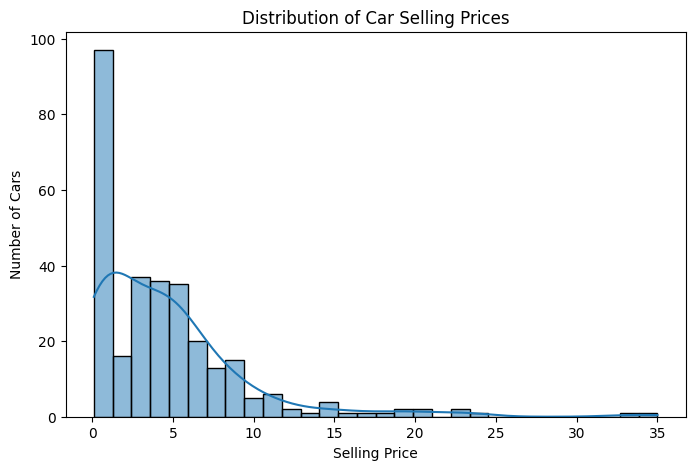

In [40]:

plt.figure(figsize=(8, 5))

sns.histplot(
    df['Selling_Price'],
    bins=30,
    kde=True
)

plt.title('Distribution of Car Selling Prices')
plt.xlabel('Selling Price')
plt.ylabel('Number of Cars')
plt.show()


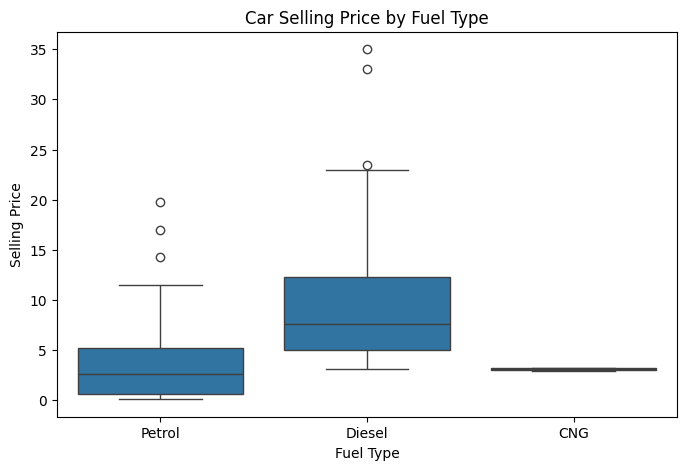

In [41]:

plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df,
    x='Fuel_Type',
    y='Selling_Price'
)

plt.title('Car Selling Price by Fuel Type')
plt.xlabel('Fuel Type')
plt.ylabel('Selling Price')
plt.show()


In [42]:

# Remove rows where selling price is missing
df = df.dropna(subset=['Selling_Price'])

# Separate input features and target
X = df.drop(columns=['Selling_Price'])
y = df['Selling_Price']

# Identify numerical and categorical columns
numerical_columns = X.select_dtypes(
    include=np.number
).columns.tolist()

categorical_columns = X.select_dtypes(
    exclude=np.number
).columns.tolist()

print("Numerical features:", numerical_columns)
print("Categorical features:", categorical_columns)

print("\nInput shape:", X.shape)
print("Target shape:", y.shape)


Numerical features: ['Year', 'Present_Price', 'Driven_kms', 'Owner']
Categorical features: ['Car_Name', 'Fuel_Type', 'Selling_type', 'Transmission']

Input shape: (299, 8)
Target shape: (299,)


In [43]:

# Numerical preprocessing
numerical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median'))
])

# Categorical preprocessing
categorical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(handle_unknown='ignore'))
])

# Combine preprocessing
preprocessor = ColumnTransformer(
    transformers=[
        ('num', numerical_transformer, numerical_columns),
        ('cat', categorical_transformer, categorical_columns)
    ]
)

print("Data preprocessing pipeline created successfully!")


Data preprocessing pipeline created successfully!


In [44]:

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])


Training samples: 239
Testing samples: 60


In [45]:

linear_model = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('model', LinearRegression())
])

linear_model.fit(X_train, y_train)

print("Linear Regression model trained successfully!")


Linear Regression model trained successfully!


In [46]:

rf_model = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('model', RandomForestRegressor(
        n_estimators=100,
        random_state=42,
        n_jobs=-1
    ))
])

rf_model.fit(X_train, y_train)

print("Random Forest model trained successfully!")


Random Forest model trained successfully!


In [47]:

# Generate predictions
linear_predictions = linear_model.predict(X_test)
rf_predictions = rf_model.predict(X_test)

# Evaluation function
def evaluate_model(name, actual, predicted):
    mae = mean_absolute_error(actual, predicted)
    rmse = np.sqrt(mean_squared_error(actual, predicted))
    r2 = r2_score(actual, predicted)

    print("\n", name)
    print("MAE:", round(mae, 2))
    print("RMSE:", round(rmse, 2))
    print("R2 Score:", round(r2, 4))

evaluate_model(
    "Linear Regression",
    y_test,
    linear_predictions
)

evaluate_model(
    "Random Forest Regression",
    y_test,
    rf_predictions
)



 Linear Regression
MAE: 1.41
RMSE: 2.43
R2 Score: 0.7706

 Random Forest Regression
MAE: 1.32
RMSE: 3.17
R2 Score: 0.6094


In [48]:

comparison = pd.DataFrame({
    'Model': ['Linear Regression', 'Random Forest'],
    'MAE': [
        mean_absolute_error(y_test, linear_predictions),
        mean_absolute_error(y_test, rf_predictions)
    ],
    'RMSE': [
        np.sqrt(mean_squared_error(y_test, linear_predictions)),
        np.sqrt(mean_squared_error(y_test, rf_predictions))
    ],
    'R2 Score': [
        r2_score(y_test, linear_predictions),
        r2_score(y_test, rf_predictions)
    ]
})

display(comparison)


,Model,MAE,RMSE,R2 Score
0,Linear Regression,1.412146,2.431628,0.770583
1,Random Forest,1.319572,3.172669,0.609447


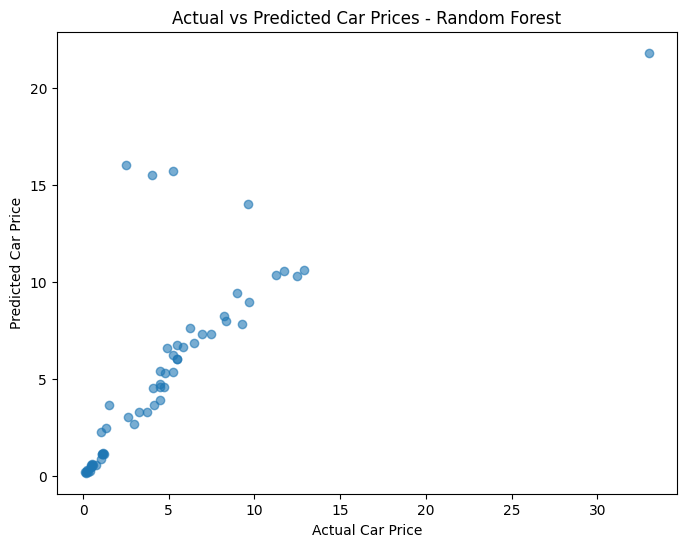

In [49]:

plt.figure(figsize=(8, 6))

plt.scatter(
    y_test,
    rf_predictions,
    alpha=0.6
)

plt.xlabel("Actual Car Price")
plt.ylabel("Predicted Car Price")
plt.title("Actual vs Predicted Car Prices - Random Forest")

plt.show()


In [50]:

sample_car = X_test.iloc[[0]]

sample_prediction = rf_model.predict(sample_car)[0]
actual_price = y_test.iloc[0]

print("Actual Car Price:", actual_price)
print("Predicted Car Price:", round(sample_prediction, 2))


Actual Car Price: 8.99
Predicted Car Price: 9.4


In [51]:

import joblib

joblib.dump(rf_model, 'car_price_prediction_model.pkl')

print("Model saved successfully!")


Model saved successfully!
